# Employee Attrition Prediction — Notebook 2: Modelling, Evaluation & Deployment

Covers steps **3 (feature engineering, splitting, encoding/scaling), 4, 5, 6, 8 and 10** of the assignment.
It reads the cleaned data produced by `01_eda.ipynb`, so run that notebook first.

In [1]:
# ==========================================================
# SETUP
# ==========================================================
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve,
                             average_precision_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, train_test_split, validation_curve)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

ROOT = Path.cwd() if (Path.cwd() / "data_ibm").exists() else Path.cwd().parent
CLEAN_PATH = ROOT / "data_ibm" / "attrition_clean.csv"
BUNDLE_PATH = ROOT / "attrition_deployment_bundle.pkl"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

SEED = 42
TARGET = "Attrition"

data = pd.read_csv(CLEAN_PATH)
print(f"Cleaned data: {data.shape[0]} rows x {data.shape[1]} columns | attrition rate {data[TARGET].eq('Yes').mean():.1%}")

Cleaned data: 1470 rows x 28 columns | attrition rate 16.1%


## 3.3 Feature Engineering — create new features

The EDA showed that attrition is driven by *relative* situations (paid little **for the level**, stuck in the same role, overtime **combined with** poor balance) that single raw columns only partly capture. We create 8 features:

| New feature | Formula | Idea |
|---|---|---|
| `Overall_Satisfaction` | mean of Environment, Job, Relationship satisfaction and Work-Life Balance | one overall happiness score |
| `Income_per_Level` | MonthlyIncome / JobLevel | underpaid compared with others at the same level |
| `Tenure_Ratio` | YearsAtCompany / TotalWorkingYears | share of the career spent at this company (loyalty) |
| `Promotion_Stagnation` | YearsSinceLastPromotion / (YearsAtCompany + 1) | stuck without promotion |
| `Role_Stagnation` | YearsInCurrentRole / (YearsAtCompany + 1) | stuck in the same role |
| `Job_Hopping_Rate` | NumCompaniesWorked / (TotalWorkingYears + 1) | history of changing employers |
| `Overtime_Strain` | OverTime (0/1) × (5 − WorkLifeBalance) | overtime made worse by poor balance (0–4) |
| `Age_Group` | Age bands: Under 30, 30-39, 40-49, 50+ | captures the young-employee risk seen in EDA |

The same function is copied into the Streamlit app (`app/app.py`) so the app builds exactly the features the model was trained on.

Shape after feature engineering: (1470, 36)


,Overall_Satisfaction,Income_per_Level,Tenure_Ratio,Promotion_Stagnation,Role_Stagnation,Job_Hopping_Rate,Overtime_Strain,Age_Group
0,2.00,2996.5,0.750000,0.000000,0.571429,0.888889,4,40-49
1,3.00,2565.0,1.000000,0.090909,0.636364,0.090909,0,40-49
2,3.00,2090.0,0.000000,0.000000,0.000000,0.750000,2,30-39
3,3.25,2909.0,1.000000,0.333333,0.777778,0.111111,2,30-39
4,2.50,3468.0,0.333333,0.666667,0.666667,1.285714,0,Under 30


Correlation of the new features with Attrition:
Overall_Satisfaction   -0.159
Role_Stagnation        -0.158
Income_per_Level       -0.114
Tenure_Ratio           -0.016
Promotion_Stagnation    0.010
Job_Hopping_Rate        0.200
Overtime_Strain         0.242

Attrition rate by Age_Group (%):
Age_Group
30-39       14.3
40-49        9.7
50+         13.3
Under 30    27.9


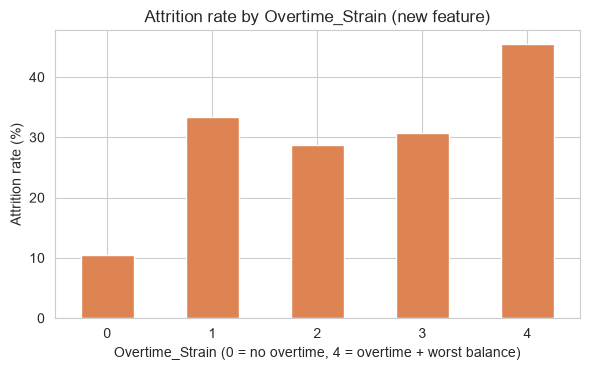

In [2]:
# ==========================================================
# 3.3 FEATURE ENGINEERING
# (the same function is used in app/app.py)
# ==========================================================
def add_features(df):
    out = df.copy()
    overtime = (out["OverTime"] == "Yes").astype(int)
    out["Overall_Satisfaction"] = out[["EnvironmentSatisfaction", "JobSatisfaction",
                                       "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)
    out["Income_per_Level"] = out["MonthlyIncome"] / out["JobLevel"]
    out["Tenure_Ratio"] = (out["YearsAtCompany"] / out["TotalWorkingYears"].replace(0, np.nan)).fillna(0).clip(0, 1)
    out["Promotion_Stagnation"] = out["YearsSinceLastPromotion"] / (out["YearsAtCompany"] + 1)
    out["Role_Stagnation"] = out["YearsInCurrentRole"] / (out["YearsAtCompany"] + 1)
    out["Job_Hopping_Rate"] = out["NumCompaniesWorked"] / (out["TotalWorkingYears"] + 1)
    out["Overtime_Strain"] = overtime * (5 - out["WorkLifeBalance"])
    out["Age_Group"] = pd.cut(out["Age"], bins=[0, 29, 39, 49, 200],
                              labels=["Under 30", "30-39", "40-49", "50+"]).astype(str)
    return out

RAW_FEATURES = [c for c in data.columns if c != TARGET]
data_fe = add_features(data)
data_fe[TARGET] = data_fe[TARGET].map({"Yes": 1, "No": 0})
new_num = ["Overall_Satisfaction", "Income_per_Level", "Tenure_Ratio", "Promotion_Stagnation",
           "Role_Stagnation", "Job_Hopping_Rate", "Overtime_Strain"]

print(f"Shape after feature engineering: {data_fe.shape}")
display(data_fe[new_num + ["Age_Group"]].head())

print("Correlation of the new features with Attrition:")
print(data_fe[new_num].corrwith(data_fe[TARGET]).round(3).sort_values().to_string())
print("\nAttrition rate by Age_Group (%):")
print(data_fe.groupby("Age_Group")[TARGET].mean().mul(100).round(1).to_string())

rate = data_fe.groupby("Overtime_Strain")[TARGET].mean().mul(100)
fig, ax = plt.subplots(figsize=(6, 3.8))
rate.plot.bar(color="#DD8452", ax=ax)
ax.set_title("Attrition rate by Overtime_Strain (new feature)")
ax.set_ylabel("Attrition rate (%)")
ax.set_xlabel("Overtime_Strain (0 = no overtime, 4 = overtime + worst balance)")
plt.xticks(rotation=0)
save_fig("07_overtime_strain")

**Feature engineering results**
- **`Overtime_Strain` is now the single strongest signal** (r = 0.24, stronger than any original column, whose best was |r| = 0.17). Attrition rises steadily with it — overtime hurts most when work-life balance is already poor.
- `Job_Hopping_Rate` (r = 0.20) is also stronger than the raw `NumCompaniesWorked`, and `Overall_Satisfaction` (r = −0.16) combines four weak survey signals into one moderate one.
- `Age_Group` confirms the EDA: **27.9%** of employees under 30 leave, about double every other group.
- `Tenure_Ratio` and `Promotion_Stagnation` are weak on their own (|r| ≤ 0.02); we keep them because they may still help in combination, and regularisation will shrink them if not.

## 3.4 Data Splitting — 70% train / 15% validation / 15% test

- **Train (70%)**: the models learn from this set; cross-validation for tuning also runs inside it.
- **Validation (15%)**: compares models and checks for overfitting.
- **Test (15%)**: used **once**, at the very end, to measure how the final model generalises.

All splits are **stratified** so each keeps the 16% attrition rate, and use a fixed `random_state` so results are reproducible.

In [3]:
# ==========================================================
# 3.4 DATA SPLITTING (stratified 70 / 15 / 15)
# ==========================================================
X = data_fe.drop(columns=[TARGET])
y = data_fe[TARGET]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, ys in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:11s}: {len(ys):5d} rows ({len(ys)/len(y):.0%}) | attrition rate {ys.mean():.1%} ({ys.sum()} leavers)")

Training   :  1029 rows (70%) | attrition rate 16.1% (166 leavers)
Validation :   220 rows (15%) | attrition rate 15.9% (35 leavers)
Test       :   221 rows (15%) | attrition rate 16.3% (36 leavers)


## 3.5 Encoding & Scaling

- **Categorical features** (8, e.g. `JobRole`, `OverTime`, `Age_Group`) → **One-Hot Encoding** (`drop="first"` avoids a redundant column; `handle_unknown="ignore"` keeps the app working if it ever sees a new category).
- **Numeric features** (27) → **StandardScaler** (mean 0, standard deviation 1), so income in dollars and 1–4 ratings are on the same scale. This matters for Logistic Regression; tree models do not need it but are not harmed.
- The encoder and scaler are **fitted on the training set only** and then applied to validation and test. Fitting on all data would leak information about the validation/test sets into training.

In [4]:
# ==========================================================
# 3.5 ENCODING & SCALING (fit on training data only)
# ==========================================================
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

print(f"Numeric features ({len(num_cols)}): {num_cols}")
print(f"\nCategorical features ({len(cat_cols)}): {cat_cols}")
print(f"\nShapes after encoding -> train {X_train_proc.shape} | val {X_val_proc.shape} | test {X_test_proc.shape}")
print(f"Scaled training means ~0: {X_train_proc[:, :len(num_cols)].mean():.3f} | std ~1: {X_train_proc[:, :len(num_cols)].std():.3f}")

Numeric features (27): ['Age', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Overall_Satisfaction', 'Income_per_Level', 'Tenure_Ratio', 'Promotion_Stagnation', 'Role_Stagnation', 'Job_Hopping_Rate', 'Overtime_Strain']

Categorical features (8): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'Age_Group']

Shapes after encoding -> train (1029, 51) | val (220, 51) | test (221, 51)
Scaled training means ~0: 0.000 | std ~1: 1.000


## 4. Algorithm Selection

The problem is **supervised binary classification** on tabular data with labels, so unsupervised (K-Means, PCA) and reinforcement learning methods do not apply. We compare three supervised models of increasing complexity, plus a dummy baseline:

| Model | Complexity | Interpretability | Computational cost | Why include it |
|---|---|---|---|---|
| Dummy (always predicts the majority class) | none | — | none | the floor every real model must beat |
| **Logistic Regression** | low (linear) | **high** — each coefficient shows a feature's direction and weight | very low | strong, explainable baseline; works well on small datasets |
| **Random Forest** | medium (many deep trees) | medium — feature importances | medium | captures non-linear effects and interactions; robust to outliers |
| **Gradient Boosting** | high (sequential trees) | medium — feature importances | medium–high | usually the most accurate on tabular data |

Neural networks were not chosen: with only 1,029 training rows they would overfit easily, cost more to train, and be the hardest to explain to HR.

**Class imbalance:** Logistic Regression and Random Forest use `class_weight="balanced"` (mistakes on leavers count ~5× more). Gradient Boosting has no `class_weight`, so we pass equivalent **sample weights**.

## 5. Model Development and Training — baseline models

Each model is trained on the training set with default hyperparameters (plus the imbalance handling above), then scored on both the **training** and **validation** sets. A large gap between them signals **overfitting**; low scores on both signal **underfitting**.

In [5]:
# ==========================================================
# 5. BASELINE TRAINING
# ==========================================================
from sklearn.utils.class_weight import compute_sample_weight
train_weights = compute_sample_weight("balanced", y_train)

baseline_models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

def metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob),
    }

rows = []
for name, model in baseline_models.items():
    start = time.perf_counter()
    if name == "Gradient Boosting":
        model.fit(X_train_proc, y_train, sample_weight=train_weights)
    else:
        model.fit(X_train_proc, y_train)
    fit_s = time.perf_counter() - start
    tr = metrics(y_train, model.predict_proba(X_train_proc)[:, 1])
    va = metrics(y_val, model.predict_proba(X_val_proc)[:, 1])
    rows.append({"Model": name, "Train ROC-AUC": tr["ROC-AUC"], "Val ROC-AUC": va["ROC-AUC"],
                 "AUC gap": tr["ROC-AUC"] - va["ROC-AUC"], "Train F1": tr["F1"], "Val F1": va["F1"],
                 "Val Recall": va["Recall"], "Val Precision": va["Precision"],
                 "Val Accuracy": va["Accuracy"], "Fit time (s)": fit_s})
baseline = pd.DataFrame(rows).set_index("Model").round(3)
print("BASELINE PERFORMANCE (threshold 0.50)")
baseline

BASELINE PERFORMANCE (threshold 0.50)


,Train ROC-AUC,Val ROC-AUC,AUC gap,Train F1,Val F1,Val Recall,Val Precision,Val Accuracy,Fit time (s)
Model,,,,,,,,,
Dummy (majority),0.500,0.500,0.000,0.000,0.000,0.000,0.000,0.841,0.000
Logistic Regression,0.886,0.807,0.079,0.564,0.489,0.629,0.400,0.791,0.033
Random Forest,1.000,0.720,0.280,0.997,0.381,0.343,0.429,0.823,0.233
Gradient Boosting,0.992,0.726,0.266,0.877,0.416,0.457,0.381,0.795,0.353


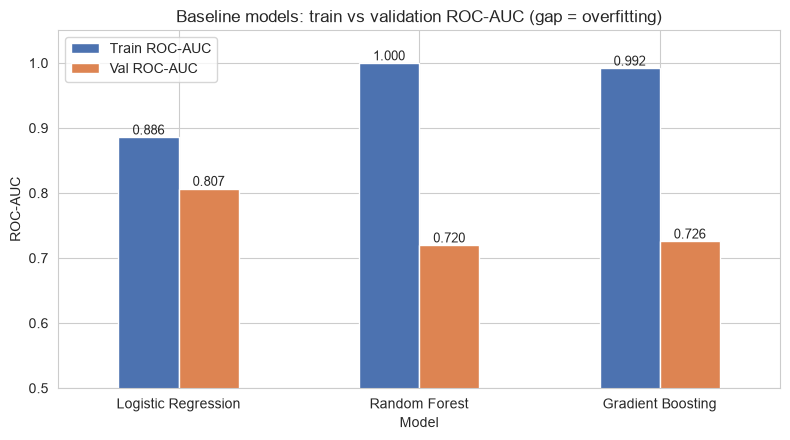

In [6]:
plot_df = baseline.drop(index="Dummy (majority)")[["Train ROC-AUC", "Val ROC-AUC"]]
ax = plot_df.plot.bar(figsize=(8, 4.5), color=["#4C72B0", "#DD8452"], rot=0)
ax.set_ylim(0.5, 1.05)
ax.set_title("Baseline models: train vs validation ROC-AUC (gap = overfitting)")
ax.set_ylabel("ROC-AUC")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
save_fig("08_baseline_overfitting")

**Baseline results — underfitting and overfitting**
- The **Dummy** model has 84% accuracy but F1 = 0 and ROC-AUC = 0.50: it never finds a leaver. This proves accuracy is the wrong metric here.
- **Logistic Regression** is the best baseline (validation ROC-AUC **0.807**) and generalises well: the train–validation gap is only 0.08.
- **Random Forest is heavily overfitted**: perfect training ROC-AUC (1.000) but only 0.720 on validation — it memorised the 1,029 training employees. **Gradient Boosting** shows the same problem (0.992 → 0.726).
- None of the models underfit (all are far above 0.50), but the tree models need constraints, which the tuning below provides.

## 6. Model Evaluation and Hyperparameter Tuning

### 6.1 Hyperparameter tuning

Tuning uses **5-fold stratified cross-validation inside the training set**, scored by ROC-AUC, so the validation and test sets stay unseen:

| Model | Method | Hyperparameters searched | Goal |
|---|---|---|---|
| Logistic Regression | **Grid Search** (small space, try every combination) | `C` (regularisation strength), `penalty` (L1 / L2) | find the right amount of regularisation |
| Random Forest | **Random Search** (40 random combinations) | number of trees, `max_depth`, `min_samples_leaf`, `max_features` | limit tree size to reduce overfitting |
| Gradient Boosting | **Random Search** (40 random combinations) | number of trees, `learning_rate`, `max_depth`, `min_samples_leaf`, `subsample` | slower learning + shallower trees to reduce overfitting |

In [7]:
# ==========================================================
# 6.1 HYPERPARAMETER TUNING
# ==========================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

searches = {
    "Logistic Regression": GridSearchCV(
        LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000, random_state=SEED),
        {"C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10], "penalty": ["l1", "l2"]},
        cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True),
    "Random Forest": RandomizedSearchCV(
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        {"n_estimators": [200, 300, 500], "max_depth": [3, 5, 8, 12, None],
         "min_samples_leaf": [1, 2, 4, 8, 16], "max_features": ["sqrt", "log2", 0.3]},
        n_iter=40, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=SEED, return_train_score=True),
    "Gradient Boosting": RandomizedSearchCV(
        GradientBoostingClassifier(random_state=SEED),
        {"n_estimators": [100, 200, 300, 500], "learning_rate": [0.01, 0.03, 0.05, 0.1],
         "max_depth": [1, 2, 3], "min_samples_leaf": [5, 10, 20, 40], "subsample": [0.7, 0.85, 1.0]},
        n_iter=40, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=SEED, return_train_score=True),
}

tuned_models, rows = {}, []
for name, search in searches.items():
    start = time.perf_counter()
    if name == "Gradient Boosting":
        search.fit(X_train_proc, y_train, sample_weight=train_weights)
    else:
        search.fit(X_train_proc, y_train)
    tuned_models[name] = search.best_estimator_
    best = search.cv_results_["rank_test_score"].argmin()
    val_prob = search.best_estimator_.predict_proba(X_val_proc)[:, 1]
    rows.append({"Model": name,
                 "Search": "Grid" if isinstance(search, GridSearchCV) else "Random",
                 "CV train ROC-AUC": search.cv_results_["mean_train_score"][best],
                 "CV ROC-AUC": search.best_score_,
                 "Val ROC-AUC": roc_auc_score(y_val, val_prob),
                 "Baseline Val ROC-AUC": baseline.loc[name, "Val ROC-AUC"],
                 "Val PR-AUC": average_precision_score(y_val, val_prob),
                 "Search time (s)": time.perf_counter() - start})
    print(f"{name:20s} best params: {search.best_params_}")

tuned = pd.DataFrame(rows).set_index("Model")
tuned["CV gap (train - CV)"] = tuned["CV train ROC-AUC"] - tuned["CV ROC-AUC"]
tuned = tuned.round(3)
tuned

Logistic Regression  best params: {'C': 0.03, 'penalty': 'l2'}


Random Forest        best params: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}


Gradient Boosting    best params: {'subsample': 0.7, 'n_estimators': 500, 'min_samples_leaf': 5, 'max_depth': 1, 'learning_rate': 0.03}


,Search,CV train ROC-AUC,CV ROC-AUC,Val ROC-AUC,Baseline Val ROC-AUC,Val PR-AUC,Search time (s),CV gap (train - CV)
Model,,,,,,,,
Logistic Regression,Grid,0.871,0.835,0.784,0.807,0.547,9.536,0.036
Random Forest,Random,1.000,0.826,0.726,0.720,0.324,45.614,0.174
Gradient Boosting,Random,0.914,0.832,0.752,0.726,0.438,36.911,0.082


### 6.2 Underfitting / overfitting check — validation curve

A validation curve shows how training and cross-validation scores change with model complexity. For Logistic Regression, complexity is controlled by `C` (small C = strong regularisation = simpler model).

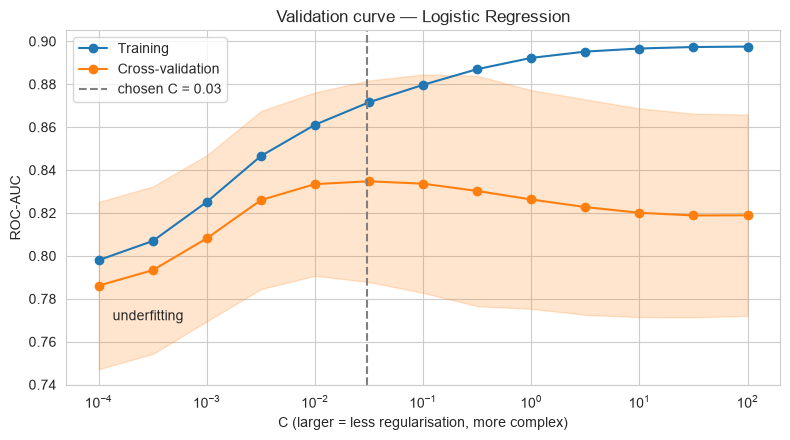

C=   0.0001  train 0.798  cv 0.786  gap 0.012
C=   0.0003  train 0.807  cv 0.793  gap 0.014
C=   0.0010  train 0.825  cv 0.808  gap 0.017
C=   0.0032  train 0.847  cv 0.826  gap 0.021
C=   0.0100  train 0.861  cv 0.833  gap 0.028
C=   0.0316  train 0.872  cv 0.835  gap 0.037
C=   0.1000  train 0.880  cv 0.834  gap 0.046
C=   0.3162  train 0.887  cv 0.830  gap 0.057
C=   1.0000  train 0.892  cv 0.826  gap 0.066
C=   3.1623  train 0.895  cv 0.823  gap 0.072
C=  10.0000  train 0.897  cv 0.820  gap 0.077
C=  31.6228  train 0.897  cv 0.819  gap 0.079
C= 100.0000  train 0.898  cv 0.819  gap 0.079


In [8]:
# ==========================================================
# 6.2 VALIDATION CURVE (Logistic Regression, C)
# ==========================================================
C_range = np.logspace(-4, 2, 13)
train_sc, cv_sc = validation_curve(
    LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000, random_state=SEED,
                       penalty=tuned_models["Logistic Regression"].penalty),
    X_train_proc, y_train, param_name="C", param_range=C_range, cv=cv, scoring="roc_auc", n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(C_range, train_sc.mean(1), "o-", label="Training")
ax.semilogx(C_range, cv_sc.mean(1), "o-", label="Cross-validation")
ax.fill_between(C_range, cv_sc.mean(1) - cv_sc.std(1), cv_sc.mean(1) + cv_sc.std(1), alpha=0.2, color="C1")
ax.axvline(tuned_models["Logistic Regression"].C, ls="--", c="grey", label=f"chosen C = {tuned_models['Logistic Regression'].C}")
ax.set_xlabel("C (larger = less regularisation, more complex)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Validation curve — Logistic Regression")
ax.annotate("underfitting", (C_range[0], cv_sc.mean(1)[0]), xytext=(10, -25), textcoords="offset points")
ax.legend()
save_fig("09_validation_curve_lr")
for c, t, v in zip(C_range, train_sc.mean(1), cv_sc.mean(1)):
    print(f"C={c:9.4f}  train {t:.3f}  cv {v:.3f}  gap {t - v:.3f}")

### 6.3 Model comparison on the validation set

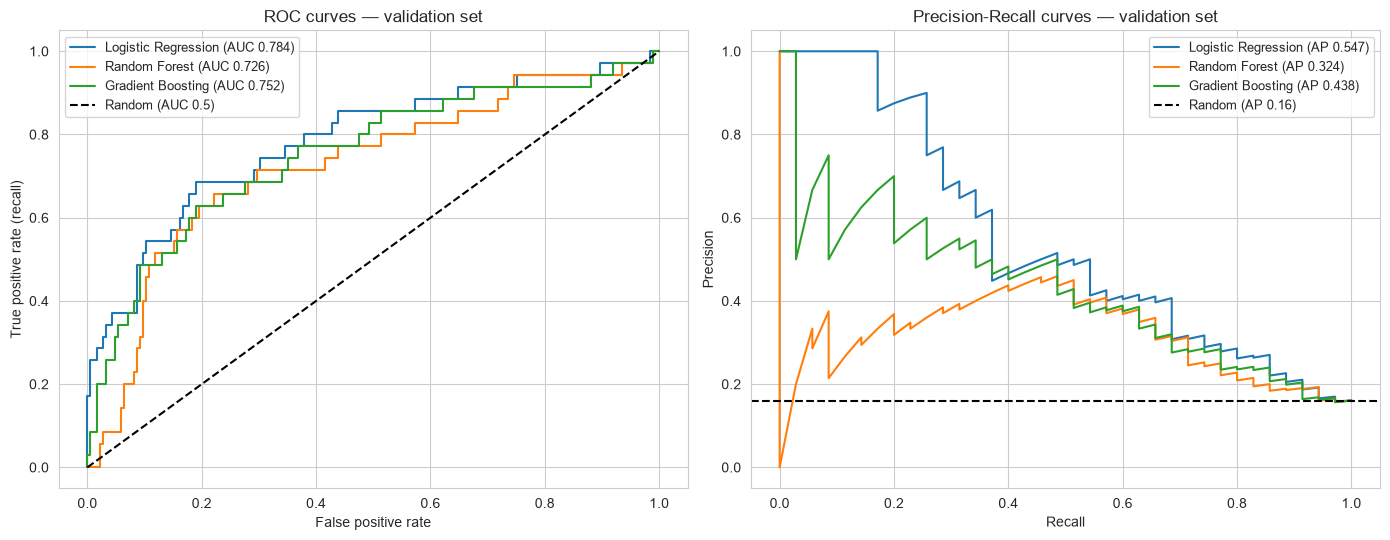

Selected final model: Logistic Regression  (validation ROC-AUC 0.784)


In [9]:
# ==========================================================
# 6.3 ROC AND PRECISION-RECALL CURVES (validation set)
# ==========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, model in tuned_models.items():
    prob = model.predict_proba(X_val_proc)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_val, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y_val, prob)
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_val, prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random (AUC 0.5)")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curves — validation set")
axes[1].axhline(y_val.mean(), ls="--", c="k", label=f"Random (AP {y_val.mean():.2f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves — validation set")
for ax in axes:
    ax.legend(loc="best", fontsize=9)
save_fig("10_roc_pr_validation")

# Selection rule: highest validation ROC-AUC; if within 0.01 of the best, prefer the simpler model
order = ["Logistic Regression", "Random Forest", "Gradient Boosting"]   # simplest first
best_auc = tuned["Val ROC-AUC"].max()
final_name = next(m for m in order if tuned.loc[m, "Val ROC-AUC"] >= best_auc - 0.01)
final_model = tuned_models[final_name]
print(f"Selected final model: {final_name}  (validation ROC-AUC {tuned.loc[final_name, 'Val ROC-AUC']:.3f})")

**Tuning results and model choice**
- Tuning **reduced overfitting** in both tree models: the Gradient Boosting gap fell from 0.27 to 0.08 (it chose very shallow trees, `max_depth=1`, and a slow learning rate) and its validation ROC-AUC rose from 0.726 to 0.752. Random Forest improved slightly (0.720 → 0.726) but still overfits (gap 0.17).
- Logistic Regression chose `C = 0.03` (strong L2 regularisation). The validation curve shows why: below C ≈ 0.003 the model **underfits** (train and CV both low); above C ≈ 0.3 the train score keeps rising while CV falls — **overfitting**. C = 0.03 sits at the CV peak (0.835).
- Its validation ROC-AUC (0.784) is slightly lower than the untuned baseline (0.807). With only 35 leavers in the validation set, a difference of 0.02 is within noise; the 5-fold CV score (computed on 5× more data) is the more reliable guide and it favours the tuned model.
- **Final model: tuned Logistic Regression.** It has the best validation ROC-AUC and PR-AUC of the tuned models, the smallest overfitting gap, trains in milliseconds, and — important for HR — its coefficients explain *why* an employee is flagged.

### 6.4 Decision threshold

The model outputs a probability. The default cut-off of 0.50 is not right for an imbalanced problem where missing a leaver costs more than a false alarm. We choose the threshold that gives the **best F1 while keeping recall ≥ 0.70** (our success criterion).

To avoid tuning the threshold on the small validation set (only 35 leavers), we use **out-of-fold predictions on the training set**: 5-fold cross-validation gives every training employee a probability from a model that did not see them. The chosen threshold is then checked on the validation set.

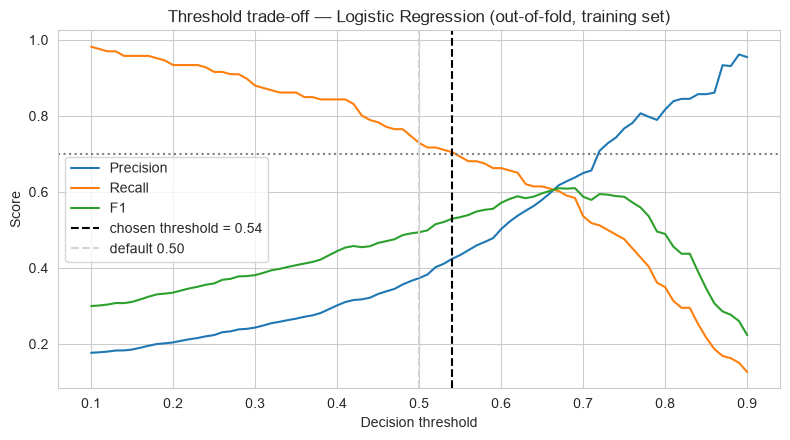

Chosen threshold: 0.54

VALIDATION SET — Logistic Regression


,Threshold 0.50,Threshold 0.54
Accuracy,0.768,0.791
Precision,0.375,0.400
Recall,0.686,0.629
F1,0.485,0.489
ROC-AUC,0.784,0.784


In [10]:
# ==========================================================
# 6.4 THRESHOLD SELECTION (out-of-fold training predictions)
# ==========================================================
fit_params = {"sample_weight": train_weights} if final_name == "Gradient Boosting" else None
oof_prob = cross_val_predict(sklearn.base.clone(final_model), X_train_proc, y_train, cv=cv,
                             method="predict_proba", params=fit_params)[:, 1]

thresholds = np.round(np.arange(0.10, 0.91, 0.01), 2)
curve = pd.DataFrame([{"Threshold": t,
                       "Precision": precision_score(y_train, oof_prob >= t, zero_division=0),
                       "Recall": recall_score(y_train, oof_prob >= t),
                       "F1": f1_score(y_train, oof_prob >= t)} for t in thresholds])
ok = curve[curve["Recall"] >= 0.70]
THRESHOLD = float(ok.loc[ok["F1"].idxmax(), "Threshold"])

fig, ax = plt.subplots(figsize=(8, 4.5))
for col in ["Precision", "Recall", "F1"]:
    ax.plot(curve["Threshold"], curve[col], label=col)
ax.axhline(0.70, ls=":", c="grey")
ax.axvline(THRESHOLD, ls="--", c="k", label=f"chosen threshold = {THRESHOLD:.2f}")
ax.axvline(0.5, ls="--", c="lightgrey", label="default 0.50")
ax.set(xlabel="Decision threshold", ylabel="Score", title=f"Threshold trade-off — {final_name} (out-of-fold, training set)")
ax.legend()
save_fig("11_threshold_tradeoff")

val_prob = final_model.predict_proba(X_val_proc)[:, 1]
compare = pd.DataFrame({"Threshold 0.50": metrics(y_val, val_prob, 0.5),
                        f"Threshold {THRESHOLD:.2f}": metrics(y_val, val_prob, THRESHOLD)}).round(3)
print(f"Chosen threshold: {THRESHOLD:.2f}")
print(f"\nVALIDATION SET — {final_name}")
compare

**Threshold choice:** on the out-of-fold training predictions, **0.54** gives the best F1 while keeping recall ≥ 0.70. On validation it lifts F1 slightly (0.485 → 0.489) and precision (0.375 → 0.400), at the cost of recall (0.686 → 0.629 — 2 of 35 leavers). Validation recall falls a little short of 0.70, a reminder that with 35 leavers each person changes recall by ~3 points; the final judgement is the test set below.

## 8. Model Testing and Deployment

### 8.1 Final evaluation on the unseen test set

The test set has not been used for any decision so far. We now score the final model on it **once**, with the same metrics and threshold as on validation.

In [11]:
# ==========================================================
# 8.1 FINAL TEST
# ==========================================================
final_metrics = pd.DataFrame({
    "Train": metrics(y_train, final_model.predict_proba(X_train_proc)[:, 1], THRESHOLD),
    "Validation": metrics(y_val, val_prob, THRESHOLD),
    "Test": metrics(y_test, final_model.predict_proba(X_test_proc)[:, 1], THRESHOLD),
}).round(3)
print(f"FINAL MODEL: {final_name} | threshold = {THRESHOLD:.2f}\n")
display(final_metrics)

test_prob = final_model.predict_proba(X_test_proc)[:, 1]
test_pred = (test_prob >= THRESHOLD).astype(int)
t = final_metrics["Test"]
criteria = pd.DataFrame({
    "Target": [0.80, 0.70, 0.50],
    "Test result": [t["ROC-AUC"], t["Recall"], t["F1"]],
}, index=["ROC-AUC", "Recall", "F1"])
criteria["Met?"] = np.where(criteria["Test result"] >= criteria["Target"], "MET", "NOT MET")
print("SUCCESS CRITERIA (test set)")
display(criteria)

print("Classification report (test set):")
print(classification_report(y_test, test_pred, target_names=["Stayed", "Left"]))

FINAL MODEL: Logistic Regression | threshold = 0.54



,Train,Validation,Test
Accuracy,0.812,0.791,0.774
Precision,0.452,0.400,0.394
Recall,0.759,0.629,0.722
F1,0.566,0.489,0.510
ROC-AUC,0.868,0.784,0.825


SUCCESS CRITERIA (test set)


,Target,Test result,Met?
ROC-AUC,0.8,0.825,MET
Recall,0.7,0.722,MET
F1,0.5,0.510,MET


Classification report (test set):
              precision    recall  f1-score   support

      Stayed       0.94      0.78      0.85       185
        Left       0.39      0.72      0.51        36

    accuracy                           0.77       221
   macro avg       0.66      0.75      0.68       221
weighted avg       0.85      0.77      0.80       221



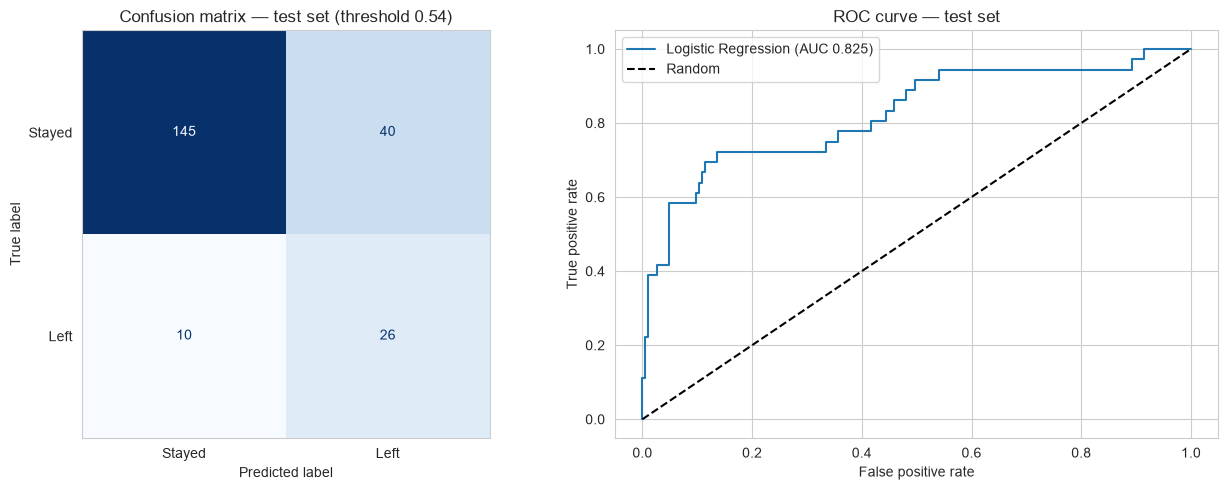

Of 36 employees who left, the model flagged 26 and missed 10.
Of 185 employees who stayed, 40 were flagged for review and 145 were correctly left alone.
HR would review 66 of 221 employees (30%); 39% of them really leave (vs 16% if picked at random).


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=["Stayed", "Left"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].grid(False)
axes[0].set_title(f"Confusion matrix — test set (threshold {THRESHOLD:.2f})")
fpr, tpr, _ = roc_curve(y_test, test_prob)
axes[1].plot(fpr, tpr, label=f"{final_name} (AUC {roc_auc_score(y_test, test_prob):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve — test set")
axes[1].legend()
save_fig("12_test_confusion_roc")

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
print(f"Of {tp + fn} employees who left, the model flagged {tp} and missed {fn}.")
print(f"Of {tn + fp} employees who stayed, {fp} were flagged for review and {tn} were correctly left alone.")
print(f"HR would review {tp + fp} of {len(y_test)} employees ({(tp + fp)/len(y_test):.0%}); {tp/(tp+fp):.0%} of them really leave "
      f"(vs {y_test.mean():.0%} if picked at random).")

**Test results — all three success criteria are met**

| Metric | Target | Test |
|---|---|---|
| ROC-AUC | ≥ 0.80 | **0.825** ✔ |
| Recall | ≥ 0.70 | **0.722** ✔ |
| F1 | ≥ 0.50 | **0.510** ✔ |

- **Generalisation:** test ROC-AUC (0.825) is close to the cross-validation estimate (0.835) and below training (0.868) by only 0.04, so the model is not overfitted.
- **In practice:** the model catches **26 of the 36** leavers. HR would review 66 of 221 employees (30%), and 39% of those really leave — **2.4× better than picking at random** (16%).
- **Honest caveats:** recall and F1 pass by a small margin, and the test set has only 36 leavers, so results could vary by a few points on another sample. Precision is modest (39%): about 3 in 5 flagged employees would have stayed. For a low-cost action like a stay interview this is acceptable; it would not be for a costly action.

### 8.2 What drives the predictions?

**Permutation importance** on the validation set: shuffle one feature at a time and measure how much ROC-AUC drops. A big drop means the model relies on that feature. It works for any model type.

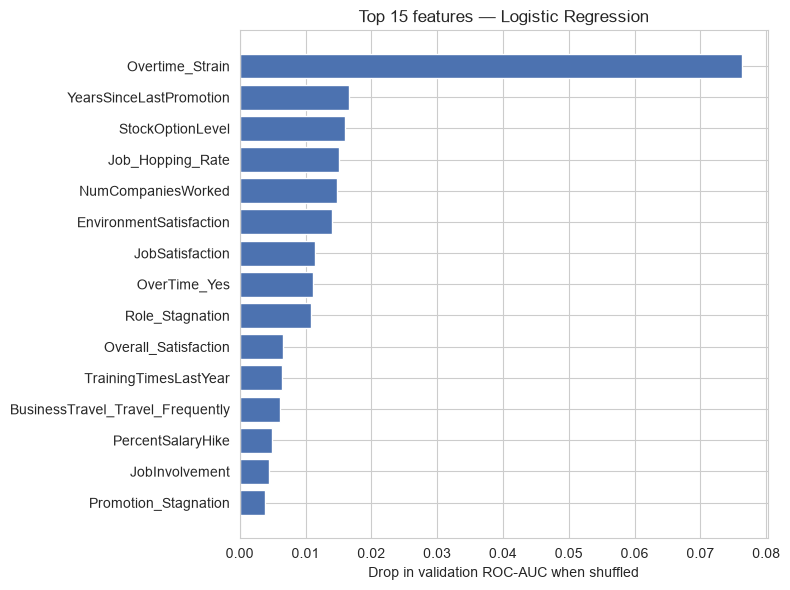

Overtime_Strain                     0.0764
YearsSinceLastPromotion             0.0166
StockOptionLevel                    0.0160
Job_Hopping_Rate                    0.0151
NumCompaniesWorked                  0.0147
EnvironmentSatisfaction             0.0141
JobSatisfaction                     0.0114
OverTime_Yes                        0.0111
Role_Stagnation                     0.0108
Overall_Satisfaction                0.0065
TrainingTimesLastYear               0.0065
BusinessTravel_Travel_Frequently    0.0062
PercentSalaryHike                   0.0049
JobInvolvement                      0.0044
Promotion_Stagnation                0.0038

Largest coefficients (+ raises the risk of leaving, - lowers it):
Overtime_Strain                      0.445
Department_Research & Development   -0.393
Role_Stagnation                     -0.296
JobRole_Research Scientist          -0.291
JobRole_Laboratory Technician        0.278
YearsSinceLastPromotion              0.278
BusinessTravel_Travel_Frequent

In [13]:
# ==========================================================
# 8.2 FEATURE IMPORTANCE
# ==========================================================
perm = permutation_importance(final_model, X_val_proc, y_val, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color="#4C72B0")
ax.set(xlabel="Drop in validation ROC-AUC when shuffled", title=f"Top 15 features — {final_name}")
save_fig("13_feature_importance")
print(importance.head(15).round(4).to_string())

if final_name == "Logistic Regression":
    coefs = pd.Series(final_model.coef_[0], index=feature_names)
    print("\nLargest coefficients (+ raises the risk of leaving, - lowers it):")
    print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).round(3).to_string())

**What drives attrition (according to the model)**
- **`Overtime_Strain`** — our engineered feature — is by far the most important input and has the largest coefficient: overtime combined with poor work-life balance is the strongest risk factor.
- Other risk-raising factors: long time since last promotion, frequent business travel, a history of job-hopping, working as a Laboratory Technician.
- Protective factors: stock options, higher overall satisfaction, job involvement, working in R&D.
- These match the EDA, which gives confidence the model has learned real patterns rather than noise.
- **HR actions this suggests:** review overtime and workload, promotion timelines and stock-option eligibility for junior staff.

### 8.3 Save the model and simulate production use

Everything the app needs is saved in one file, `attrition_deployment_bundle.pkl`:
- the fitted **preprocessor** (scaler + one-hot encoder) and the trained **model**;
- the chosen **threshold** and the test metrics (shown in the app sidebar, so the app never shows stale numbers);
- the **valid input ranges and categories** from the training data (the app's sliders use them);
- **training-data statistics**, used by the app to detect data drift (Step 10).

In [14]:
# ==========================================================
# 8.3 SAVE DEPLOYMENT BUNDLE
# ==========================================================
raw_train = X_train[RAW_FEATURES]
raw_num = raw_train.select_dtypes("number").columns.tolist()
raw_cat = raw_train.select_dtypes(exclude="number").columns.tolist()

bundle = {
    "preprocessor": preprocessor,
    "model": final_model,
    "model_name": final_name,
    "best_params": searches[final_name].best_params_,
    "threshold": THRESHOLD,
    "test_metrics": final_metrics["Test"].to_dict(),
    "raw_features": RAW_FEATURES,
    "numeric_ranges": {c: {"min": int(raw_train[c].min()), "max": int(raw_train[c].max()),
                           "median": int(raw_train[c].median())} for c in raw_num},
    "categories": {c: sorted(raw_train[c].unique().tolist()) for c in raw_cat},
    "train_stats": {"mean": raw_train[raw_num].mean().round(4).to_dict(),
                    "std": raw_train[raw_num].std().round(4).to_dict(),
                    "high_risk_rate": float((oof_prob >= THRESHOLD).mean())},
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, BUNDLE_PATH)
print(f"Saved: {BUNDLE_PATH.relative_to(ROOT)}  ({BUNDLE_PATH.stat().st_size/1024:.0f} KB)")

# ---- Simulate production: reload the file and score raw employee records ----
loaded = joblib.load(BUNDLE_PATH)
sample = X_test[RAW_FEATURES].iloc[:5]           # raw inputs only, like the app sends
probs = loaded["model"].predict_proba(loaded["preprocessor"].transform(add_features(sample)))[:, 1]
print("\nINFERENCE DEMO (5 test employees)")
for i, (p, actual) in enumerate(zip(probs, y_test.iloc[:5]), 1):
    flag = "HIGH RISK (flag for HR)" if p >= loaded["threshold"] else "LOW RISK"
    print(f"Employee #{i} | probability {p:6.1%} -> {flag:24s} | actually left: {'Yes' if actual else 'No'}")

assert np.allclose(probs, test_prob[:5]), "Saved bundle does not reproduce the notebook predictions"
print("\nCheck passed: the saved bundle reproduces the notebook's predictions.")

Saved: attrition_deployment_bundle.pkl  (11 KB)

INFERENCE DEMO (5 test employees)
Employee #1 | probability  46.1% -> LOW RISK                 | actually left: No
Employee #2 | probability  31.8% -> LOW RISK                 | actually left: No
Employee #3 | probability  56.2% -> HIGH RISK (flag for HR)  | actually left: No
Employee #4 | probability  95.3% -> HIGH RISK (flag for HR)  | actually left: Yes
Employee #5 | probability  66.4% -> HIGH RISK (flag for HR)  | actually left: No

Check passed: the saved bundle reproduces the notebook's predictions.


### 8.4 Deployment with Streamlit

The model is served by a **Streamlit** web app, `app/app.py`:
1. HR enters an employee's details (sliders and drop-downs limited to the ranges seen in training).
2. The app builds the engineered features with the same `add_features` function, applies the saved preprocessor and model, and shows the probability, the High / Low risk flag and suggested HR actions.
3. A **Batch scoring** tab accepts a CSV export of many employees (same columns as the dataset) and returns a risk score for each — this is how the model **integrates with an existing HR system**: export staff from the HR database, score, and download the ranked list.

**Run locally** (from the project folder):
```
pip install -r requirements.txt
streamlit run app/app.py
```

**Deploy for free on Streamlit Community Cloud:** push the project to GitHub, sign in at https://share.streamlit.io, click *Create app*, choose the repository, branch `main` and main file `app/app.py`. Streamlit installs `requirements.txt` and gives the app a public URL. Full steps are in `README.md`.

## 10. Monitoring and Maintenance

After deployment we need to know whether the model is still fast, still sees the kind of data it was trained on, and is still right. The app does this in three ways (see its **Monitoring** tab):

| What | How | Where |
|---|---|---|
| **Response latency** | every prediction is timed | `monitoring/prediction_log.csv` |
| **Prediction log** | inputs, probability, flag and time of every prediction are stored | `monitoring/prediction_log.csv` |
| **Data drift** | the average of each logged input is compared with the training average (in training standard deviations); a shift above 0.5 SD is flagged | Monitoring tab |
| **Prediction drift** | share of employees flagged high-risk vs the share expected from training | Monitoring tab |
| **Feedback** | HR records whether a scored employee actually left; this builds new labelled data and measures real-world accuracy | `monitoring/feedback_log.csv` |

**Retraining plan** (not needed for this assignment): when drift alerts appear, or recall measured from feedback falls below 0.70, re-run both notebooks with the new data and redeploy the new bundle.

The cell below demonstrates the latency measurement and the drift check.

In [15]:
# ==========================================================
# 10. MONITORING DEMO: latency and drift check
# ==========================================================
# Latency: score 200 single employees one by one, as the app does
latencies = []
for i in range(200):
    row = X_test[RAW_FEATURES].iloc[[i % len(X_test)]]
    start = time.perf_counter()
    loaded["model"].predict_proba(loaded["preprocessor"].transform(add_features(row)))
    latencies.append((time.perf_counter() - start) * 1000)
print(f"Latency per prediction: median {np.median(latencies):.1f} ms | 95th percentile {np.percentile(latencies, 95):.1f} ms")

def drift_check(new_data, stats, limit=0.5):
    """Shift of each feature's mean from the training mean, in training standard deviations."""
    shift = (new_data[list(stats["mean"])].mean() - pd.Series(stats["mean"])) / pd.Series(stats["std"])
    out = pd.DataFrame({"Train mean": pd.Series(stats["mean"]), "New mean": new_data[list(stats["mean"])].mean(),
                        "Shift (SD)": shift}).round(2)
    out["Status"] = np.where(out["Shift (SD)"].abs() > limit, "DRIFT", "ok")
    return out.reindex(out["Shift (SD)"].abs().sort_values(ascending=False).index)

# 1) Test set: same population as training -> expect no drift
print("\nDrift check on the test set (same population):")
display(drift_check(X_test, loaded["train_stats"]).head(5))

# 2) Simulated new batch: the company hires many young, junior, low-paid staff
drifted = X_test.copy()
drifted["Age"] = drifted["Age"] - 8
drifted["MonthlyIncome"] = drifted["MonthlyIncome"] * 0.6
drifted["TotalWorkingYears"] = (drifted["TotalWorkingYears"] - 5).clip(lower=0)
print("Drift check on a simulated batch of younger, lower-paid employees:")
display(drift_check(drifted, loaded["train_stats"]).head(5))

Latency per prediction: median 13.6 ms | 95th percentile 16.6 ms

Drift check on the test set (same population):


,Train mean,New mean,Shift (SD),Status
RelationshipSatisfaction,2.74,2.60,-0.14,ok
Education,2.89,3.03,0.13,ok
TrainingTimesLastYear,2.74,2.87,0.10,ok
PercentSalaryHike,15.20,15.46,0.07,ok
YearsAtCompany,6.94,7.33,0.07,ok


Drift check on a simulated batch of younger, lower-paid employees:


,Train mean,New mean,Shift (SD),Status
Age,36.95,29.47,-0.82,DRIFT
MonthlyIncome,6548.27,3900.24,-0.57,DRIFT
TotalWorkingYears,11.32,7.05,-0.56,DRIFT
RelationshipSatisfaction,2.74,2.60,-0.14,ok
Education,2.89,3.03,0.13,ok


**Monitoring results**
- **Latency:** a single prediction takes roughly **10–20 ms** (exact value printed above; it varies by computer) — fast enough for an interactive app. The app logs this for every real request.
- **Drift check:** on the test set (same population as training) every feature shifts by less than 0.15 SD → no drift. On the simulated batch of younger, lower-paid staff, `Age`, `MonthlyIncome` and `TotalWorkingYears` are flagged as **DRIFT**, so the check would warn HR that the model is seeing a different workforce and should be re-validated or retrained.

## 11. Summary and Conclusions

| Step | What was done | Result |
|---|---|---|
| 1. Problem | Predict which employees will leave (binary classification) | criteria: ROC-AUC ≥ 0.80, recall ≥ 0.70, F1 ≥ 0.50 |
| 2. Data | IBM HR Analytics (Kaggle), 1,470 employees, 35 columns | replaced a synthetic dataset with no signal |
| 3. Preparation | EDA, cleaning (7 useless columns dropped), 8 new features, stratified 70/15/15 split, one-hot + scaling fitted on train | `Overtime_Strain` became the strongest feature |
| 4–5. Models | Dummy, Logistic Regression, Random Forest, Gradient Boosting | tree models overfitted; LR generalised best |
| 6. Tuning | Grid Search (LR), Random Search (RF, GB), validation curve, threshold tuning | tuned LR, C = 0.03, threshold 0.54 |
| 8. Test & deploy | One final test, saved bundle, Streamlit app | **test ROC-AUC 0.825, recall 0.722, F1 0.510 — all criteria met** |
| 10. Monitoring | latency, prediction log, drift check, HR feedback | ~10–20 ms per prediction; drift check works |

**Limitations**
- The dataset is small (237 leavers) and fictional; results on a real company's data would need re-validation.
- Precision is 39%, so most flags are false alarms; the model is a tool to prioritise conversations, not to make decisions about people.
- Features such as gender, age and marital status are used because they carry signal, but any real deployment should check the model for unfair treatment of groups before use.

**Possible improvements:** more data (several years of HR records), Bayesian optimisation over a wider search space, probability calibration, and fairness checks per group.